# Give Me Some Credit — EDA và Random Forest tập trung

Chạy trên máy local với data/cs-training.csv. Grid Search chỉ phân tích tham số trên Train. Baseline đối chứng dùng cấu hình cố định 100 cây, cùng split seed 42, median và Test của pipeline Flower Azure.

Yêu cầu local: cài requirements-centralized.txt rồi mở Jupyter từ thư mục gốc dự án. Notebook dùng hai module chia sẻ trong folder flower-app để khớp giao thức; không khởi động hay cài Flower runtime.

## 1. Thiết lập

In [1]:
from pathlib import Path
import json
import sys
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, precision_recall_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "flower-app" / "fl_app").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "flower-app" / "fl_app").is_dir():
    raise FileNotFoundError("Mở Jupyter từ thư mục gốc dự án hoặc notebooks")
SOURCE_CSV = PROJECT_ROOT / "data" / "cs-training.csv"
DATA_ROOT = PROJECT_ROOT / "data" / "experiments"
RESULT_DIR = PROJECT_ROOT / "results" / "centralized_seed42_fixed"
SEED, N_CLIENTS, TREES_PER_CLIENT = 42, 5, 20
MIN_RECALL = 0.30
RF_CONFIG = dict(max_depth=10, min_samples_leaf=5, max_features="sqrt", class_weight=None)
sys.path.insert(0, str(PROJECT_ROOT / "flower-app"))
from fl_app.protocol import TARGET, ROW_ID, load_source, prepare_split, read_checked, sha256
from fl_app.evaluation import choose_thresholds, evaluate
sns.set_theme(style="whitegrid", palette="colorblind")
print("Source:", SOURCE_CSV)
print("Baseline:", RF_CONFIG, "trees:", N_CLIENTS * TREES_PER_CLIENT)
print("pandas:", pd.__version__, "sklearn:", __import__("sklearn").__version__)

Source: C:\Users\ACER\Documents\ChatGPT\Project Cloud\data\cs-training.csv
Baseline: {'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': None} trees: 100
pandas: 2.3.3 sklearn: 1.7.2


## 2. Đọc và kiểm tra dữ liệu

In [2]:
source_with_ids, features = load_source(SOURCE_CSV)
raw = source_with_ids.drop(columns=[ROW_ID])
assert source_with_ids[ROW_ID].tolist() == list(range(len(raw)))
print(f"Nguồn: {SOURCE_CSV} | {len(raw):,} dòng × {len(features)} đặc trưng")
print("SHA-256 nguồn:", sha256(SOURCE_CSV))
print("Trùng nội dung (giữ nguyên):", int(raw.duplicated().sum()))
display(raw.head(5))

Nguồn: C:\Users\ACER\Documents\ChatGPT\Project Cloud\data\cs-training.csv | 150,000 dòng × 10 đặc trưng
SHA-256 nguồn: 1bd46da486a5708c58c7b01a034fae2a13b327f6f7b62ea7ba4fe3b5824b24ac
Trùng nội dung (giữ nguyên): 609


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


### 2.1. Tỷ lệ nhãn và giá trị thiếu

,Số dòng,Tỷ lệ (%)
Nhãn,,
0,139974,93.316
1,10026,6.684


,Số thiếu,Tỷ lệ thiếu (%)
MonthlyIncome,29731,19.820667
NumberOfDependents,3924,2.616000
RevolvingUtilizationOfUnsecuredLines,0,0.000000
age,0,0.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000
DebtRatio,0,0.000000
NumberOfOpenCreditLinesAndLoans,0,0.000000
NumberOfTimes90DaysLate,0,0.000000
NumberRealEstateLoansOrLines,0,0.000000
NumberOfTime60-89DaysPastDueNotWorse,0,0.000000


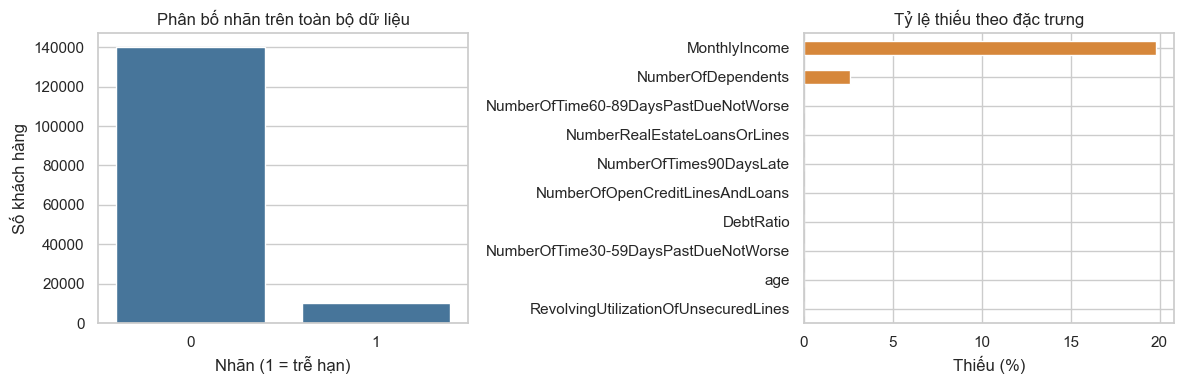

In [3]:
label_table = raw[TARGET].value_counts().sort_index().rename_axis("Nhãn").to_frame("Số dòng")
label_table["Tỷ lệ (%)"] = 100 * label_table["Số dòng"] / len(raw)
missing_table = raw[features].isna().sum().sort_values(ascending=False).to_frame("Số thiếu")
missing_table["Tỷ lệ thiếu (%)"] = 100 * missing_table["Số thiếu"] / len(raw)
display(label_table, missing_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=raw, x=TARGET, ax=axes[0], color="#3977a8")
axes[0].set(title="Phân bố nhãn trên toàn bộ dữ liệu", xlabel="Nhãn (1 = trễ hạn)", ylabel="Số khách hàng")
missing_table["Tỷ lệ thiếu (%)"].sort_values().plot.barh(ax=axes[1], color="#d6873b")
axes[1].set(title="Tỷ lệ thiếu theo đặc trưng", xlabel="Thiếu (%)", ylabel="")
plt.tight_layout()
plt.show()

### 2.2. Phân bố và ngoại lệ

,count,mean,std,min,1%,50%,95%,99%,max
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.0,0.15,1.0,1.09,50708.0
age,150000.0,52.30,14.77,0.0,24.0,52.00,78.0,87.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.0,0.00,2.0,4.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.0,0.37,2449.0,4979.04,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,0.0,5400.00,14587.6,25000.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,0.0,8.00,18.0,24.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.0,0.00,1.0,3.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.0,1.00,3.0,4.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.0,0.00,1.0,2.00,98.0
NumberOfDependents,146076.0,0.76,1.12,0.0,0.0,0.00,3.0,4.00,20.0


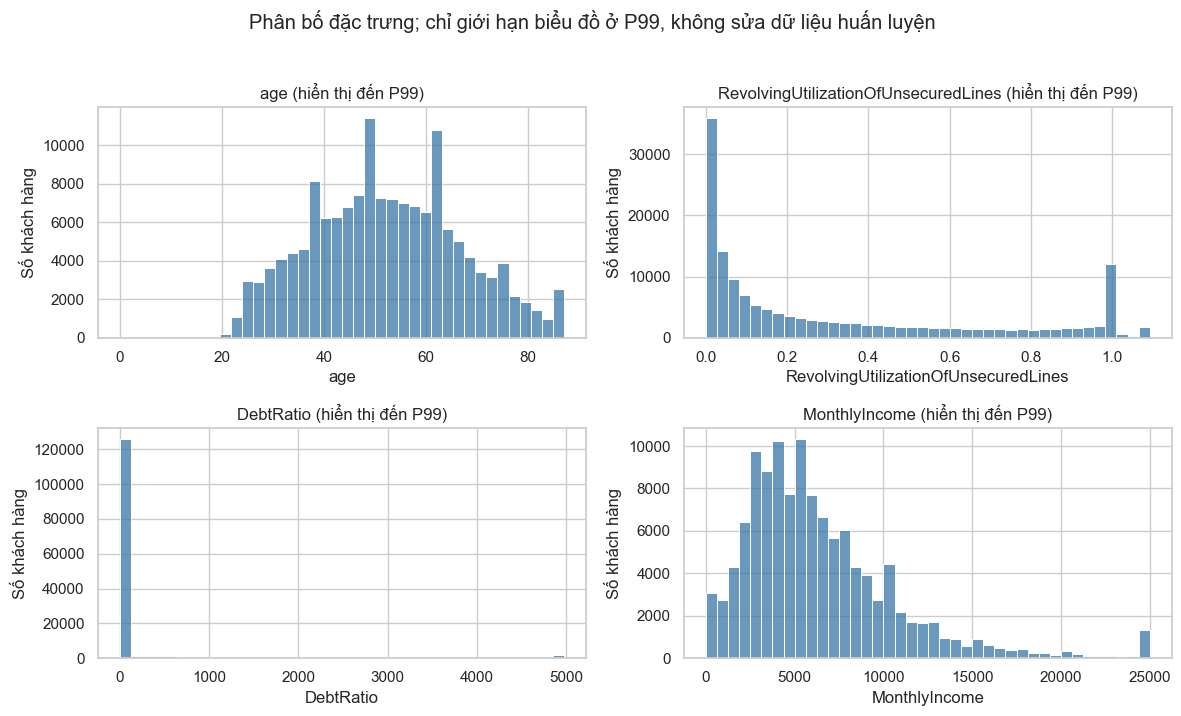

In [4]:
display(raw[features].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T.round(2))
plot_features = ["age", "RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, plot_features):
    upper = raw[col].quantile(0.99)
    series = raw[col].dropna().clip(upper=upper)
    sns.histplot(series, bins=40, ax=ax, color="#3977a8")
    ax.set(title=f"{col} (hiển thị đến P99)", xlabel=col, ylabel="Số khách hàng")
fig.suptitle("Phân bố đặc trưng; chỉ giới hạn biểu đồ ở P99, không sửa dữ liệu huấn luyện", y=1.02)
plt.tight_layout()
plt.show()

### 2.3. Quan hệ thô với nhãn

,Nhãn 0,Nhãn 1
age,52.00,45.00
RevolvingUtilizationOfUnsecuredLines,0.13,0.84
NumberOfTimes90DaysLate,0.00,0.00
NumberOfTime30-59DaysPastDueNotWorse,0.00,0.00
DebtRatio,0.36,0.43
MonthlyIncome,5466.00,4500.00


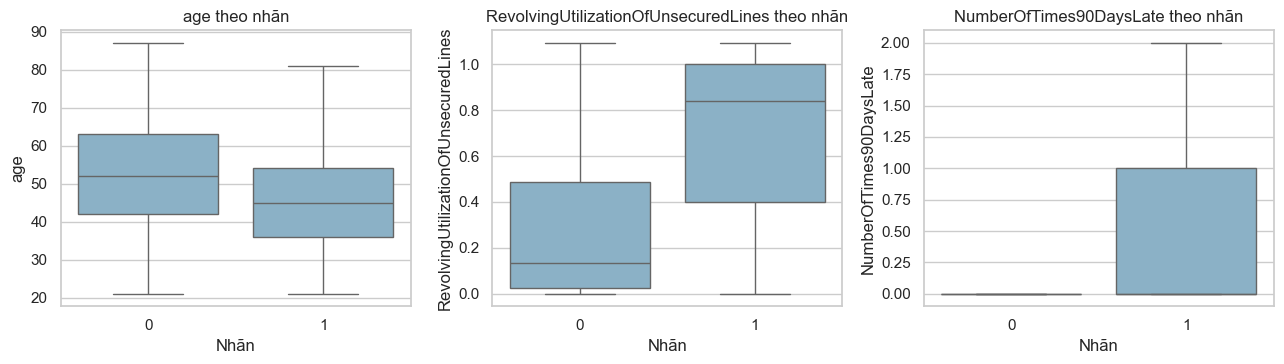

In [5]:
selected = ["age", "RevolvingUtilizationOfUnsecuredLines", "NumberOfTimes90DaysLate",
            "NumberOfTime30-59DaysPastDueNotWorse", "DebtRatio", "MonthlyIncome"]
medians = raw.groupby(TARGET)[selected].median().T
medians.columns = ["Nhãn 0", "Nhãn 1"]
display(medians.round(2))
# Ngoại lệ được giới hạn khi vẽ, các số trong bảng vẫn là trung vị gốc.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, selected[:3]):
    cap = raw[col].quantile(0.99)
    view = raw[[col, TARGET]].copy()
    view[col] = view[col].clip(upper=cap)
    sns.boxplot(data=view, x=TARGET, y=col, showfliers=False, ax=ax, color="#81b4d0")
    ax.set(xlabel="Nhãn", ylabel=col, title=f"{col} theo nhãn")
plt.tight_layout()
plt.show()

## 3. Dùng đúng split và preprocessing của Flower

Pipeline chung tạo Train 90.000, Validation 30.000, Test 30.000 bằng stratified seed 42. Median chỉ fit trên Train rồi áp dụng cho cả ba tập. Đối chiếu source row ID và SHA với manifest. Grid Search lấy giá trị thô của chính các hàng Train và fit median riêng trong từng CV fold.

In [6]:
split_dir = prepare_split(SOURCE_CSV, DATA_ROOT, SEED)
schema = json.loads((split_dir / "feature_schema.json").read_text(encoding="utf-8"))
manifest = json.loads((split_dir / "split_metadata.json").read_text(encoding="utf-8"))
assert features == schema["features"]
assert manifest["source_sha256"] == sha256(SOURCE_CSV)
assert manifest["feature_schema_sha256"] == sha256(split_dir / "feature_schema.json")
for name in ("train", "validation", "test"):
    assert manifest["split_sha256"][name] == sha256(split_dir / f"{name}.csv")
train = read_checked(split_dir / "train.csv", schema)
validation = read_checked(split_dir / "validation.csv", schema)
test = read_checked(split_dir / "test.csv", schema)
assert (len(train), len(validation), len(test)) == (90000, 30000, 30000)
assert set(train[ROW_ID]).isdisjoint(validation[ROW_ID])
assert set(train[ROW_ID]).isdisjoint(test[ROW_ID])
assert set(validation[ROW_ID]).isdisjoint(test[ROW_ID])
source_index = source_with_ids.set_index(ROW_ID)
raw_train = source_index.loc[train[ROW_ID], features]
assert np.array_equal(source_index.loc[train[ROW_ID], TARGET].to_numpy(), train[TARGET].to_numpy())
display(pd.DataFrame({"split": ["train", "validation", "test"],
                      "rows": [len(train), len(validation), len(test)],
                      "positive_rate": [f[TARGET].mean() for f in (train, validation, test)]}))
print("Split SHA-256:", manifest["split_sha256"])
print("Median fit trên Train; không loại bỏ hoặc nhân bản dòng.")

,split,rows,positive_rate
0,train,90000,0.066844
1,validation,30000,0.066833
2,test,30000,0.066833


Split SHA-256: {'train': '90bd6771fbaf930a963ba8173c462d78b4f5caa58c96de5783742a865fb46cc6', 'validation': '2bbf98bbfe750db43618b1608c733982c54848fe5296a0af001619be1ad4e863', 'test': '59db6b4e4fb5b7348d5d4bd8481a39c1e1b80991da8c0b6aca41107e6e412ac5'}
Median fit trên Train; không loại bỏ hoặc nhân bản dòng.


## 4. Grid Search trên Train — thí nghiệm tham số riêng

12 cấu hình, 3-fold stratified CV, thước đo Average Precision. Cấu hình thắng Grid Search không tự thay baseline đã đăng ký. Muốn áp dụng nó phải đổi cả Centralized và 5 Flower client rồi chạy lại Azure.

In [7]:
tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(n_estimators=N_CLIENTS * TREES_PER_CLIENT,
                                  max_features=RF_CONFIG["max_features"],
                                  random_state=SEED, n_jobs=1)),
])
param_grid = {"rf__max_depth": [8, 10, 12],
              "rf__min_samples_leaf": [2, 5],
              "rf__class_weight": [None, "balanced_subsample"]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
grid = GridSearchCV(tuning_pipeline, param_grid, scoring="average_precision",
                    cv=cv, n_jobs=1, refit=False, return_train_score=False,
                    error_score="raise")
grid.fit(raw_train, train[TARGET])
print("CV AP tốt nhất:", round(float(grid.best_score_), 4), grid.best_params_)

CV AP tốt nhất: 0.4003 {'rf__class_weight': None, 'rf__max_depth': 8, 'rf__min_samples_leaf': 2}


### 4.1. So sánh cấu hình với baseline cố định

,rank_test_score,mean_test_score,std_test_score,param_rf__max_depth,param_rf__min_samples_leaf,param_rf__class_weight,is_protocol_config
0,1,0.4003,0.0049,8,2,None,False
1,2,0.3994,0.0053,8,5,None,False
2,3,0.3992,0.0035,10,5,None,True
3,4,0.3991,0.0032,12,5,None,False
4,5,0.3970,0.0048,10,2,None,False
5,6,0.3958,0.0040,12,2,None,False
6,7,0.3840,0.0056,8,5,balanced_subsample,False
7,8,0.3798,0.0069,10,5,balanced_subsample,False
8,9,0.3766,0.0043,8,2,balanced_subsample,False
9,10,0.3747,0.0067,12,5,balanced_subsample,False


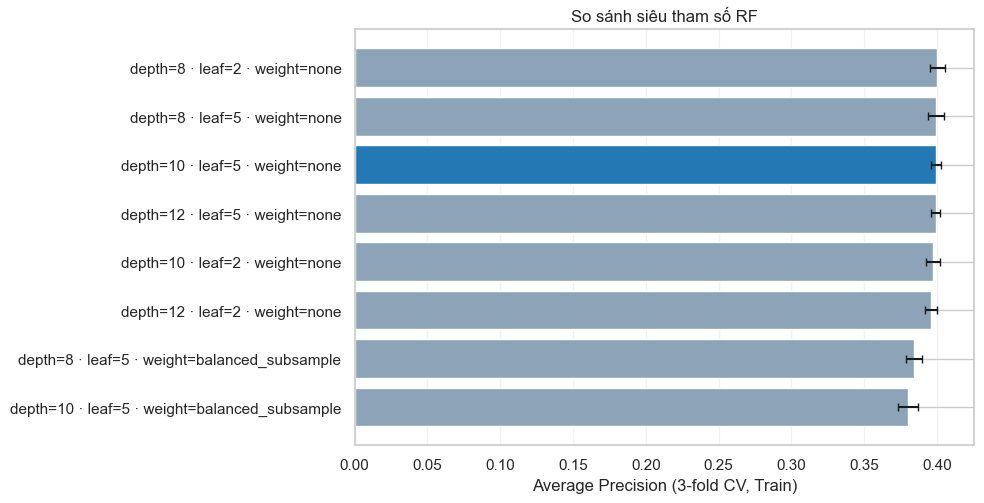

CV AP baseline cố định: 0.3992


In [8]:
cv_results = pd.DataFrame(grid.cv_results_)
cv_results["is_protocol_config"] = cv_results["params"].map(
    lambda p: p["rf__max_depth"] == RF_CONFIG["max_depth"]
    and p["rf__min_samples_leaf"] == RF_CONFIG["min_samples_leaf"]
    and p["rf__class_weight"] == RF_CONFIG["class_weight"])
assert int(cv_results["is_protocol_config"].sum()) == 1
cv_results = cv_results.sort_values("rank_test_score").reset_index(drop=True)
protocol_cv_ap = float(cv_results.loc[cv_results["is_protocol_config"], "mean_test_score"].iloc[0])
display(cv_results[["rank_test_score", "mean_test_score", "std_test_score",
                    "param_rf__max_depth", "param_rf__min_samples_leaf",
                    "param_rf__class_weight", "is_protocol_config"]].round(4))
top = cv_results.head(8).iloc[::-1]
labels = [f"depth={p['rf__max_depth']} · leaf={p['rf__min_samples_leaf']} · weight={p['rf__class_weight'] or 'none'}"
          for p in top["params"]]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(labels, top["mean_test_score"], xerr=top["std_test_score"],
        color=["#2479b5" if x else "#8ca3b8" for x in top["is_protocol_config"]], capsize=3)
ax.set(xlabel="Average Precision (3-fold CV, Train)", title="So sánh siêu tham số RF")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
print("CV AP baseline cố định:", round(protocol_cv_ap, 4))

## 5. Baseline cố định và chọn ngưỡng trên Validation

Huấn luyện 100 cây theo RF_CONFIG đã đăng ký trên 90.000 hàng Train đã điền median. Validation chọn ba ngưỡng bằng cùng hàm ServerApp sử dụng; Test không tham gia chọn.

In [9]:
start = time.perf_counter()
central = RandomForestClassifier(n_estimators=N_CLIENTS * TREES_PER_CLIENT,
                                 random_state=SEED, n_jobs=-1, **RF_CONFIG)
central.fit(train[features], train[TARGET])
central_train_seconds = time.perf_counter() - start
validation_scores = central.predict_proba(validation[features])[:, 1]
thresholds = choose_thresholds(validation[TARGET].to_numpy(), validation_scores, MIN_RECALL)
validation_rows = [{"model": "centralized", "policy": policy,
                    **evaluate(validation[TARGET].to_numpy(), validation_scores, threshold)}
                   for policy, threshold in thresholds.items()]
display(pd.DataFrame(validation_rows).round(4))
print("Centralized fit seconds:", round(central_train_seconds, 2))

,model,policy,threshold,roc_auc,average_precision,brier_score,accuracy,balanced_accuracy,precision,recall,...,f1,false_positive_rate,false_negative_rate,positive_rate,predicted_positive_rate,test_rows,tn,fp,fn,tp
0,centralized,default,0.5000,0.8639,0.3835,0.0496,0.9368,0.5783,0.5978,0.1646,...,0.2581,0.0079,0.8354,0.0668,0.0184,30000,27773,222,1675,330
1,centralized,best_f1,0.2475,0.8639,0.3835,0.0496,0.9228,0.7000,0.4257,0.4429,...,0.4341,0.0428,0.5571,0.0668,0.0695,30000,26797,1198,1117,888
2,centralized,precision_at_recall,0.3662,0.8639,0.3835,0.0496,0.9341,0.6408,0.5114,0.3022,...,0.3799,0.0207,0.6978,0.0668,0.0395,30000,27416,579,1399,606


Centralized fit seconds: 3.2


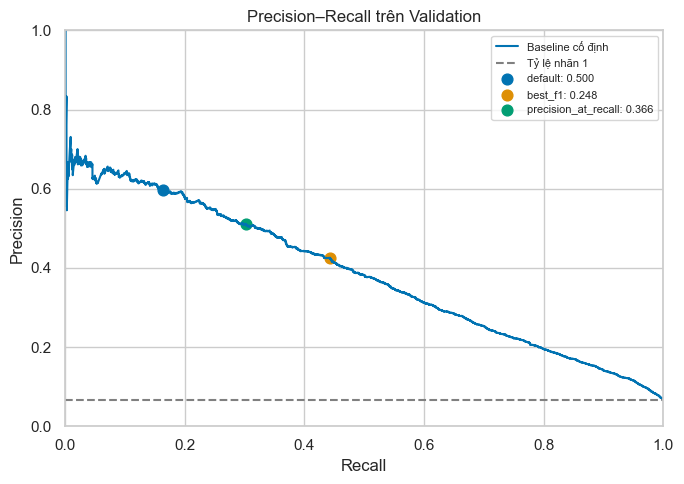

In [10]:
precision_curve, recall_curve, _ = precision_recall_curve(validation[TARGET], validation_scores)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(recall_curve, precision_curve, label="Baseline cố định")
ax.axhline(validation[TARGET].mean(), color="gray", linestyle="--", label="Tỷ lệ nhãn 1")
for row in validation_rows:
    ax.scatter(row["recall"], row["precision"], s=60,
               label=f"{row['policy']}: {row['threshold']:.3f}")
ax.set(title="Precision–Recall trên Validation", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Đánh giá trên Test chung

Không refit trên Validation. Tính metric bằng cùng fl_app.evaluation.evaluate như Flower Azure. AUC/AP không phụ thuộc ngưỡng; F1, precision, recall và confusion matrix dùng ngưỡng đã chọn trên Validation.

In [11]:
start = time.perf_counter()
central_scores = central.predict_proba(test[features])[:, 1]
test_inference_seconds = time.perf_counter() - start
test_rows = [{"model": "centralized", "policy": policy,
              **evaluate(test[TARGET].to_numpy(), central_scores, threshold)}
             for policy, threshold in thresholds.items()]
test_metrics = pd.DataFrame(test_rows)
display(test_metrics.round(4))
assert all((test_metrics["tn"] + test_metrics["fp"] +
            test_metrics["fn"] + test_metrics["tp"]) == len(test))

,model,policy,threshold,roc_auc,average_precision,brier_score,accuracy,balanced_accuracy,precision,recall,...,f1,false_positive_rate,false_negative_rate,positive_rate,predicted_positive_rate,test_rows,tn,fp,fn,tp
0,centralized,default,0.5000,0.8668,0.4034,0.0489,0.9367,0.5746,0.6004,0.1566,...,0.2484,0.0075,0.8434,0.0668,0.0174,30000,27786,209,1691,314
1,centralized,best_f1,0.2475,0.8668,0.4034,0.0489,0.9231,0.7048,0.4285,0.4529,...,0.4403,0.0433,0.5471,0.0668,0.0706,30000,26784,1211,1097,908
2,centralized,precision_at_recall,0.3662,0.8668,0.4034,0.0489,0.9341,0.6385,0.5116,0.2973,...,0.3760,0.0203,0.7027,0.0668,0.0388,30000,27426,569,1409,596


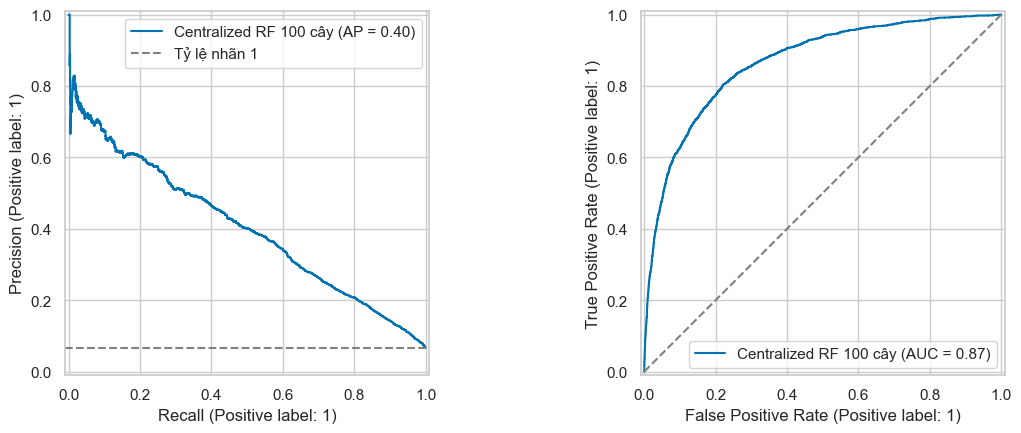

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
PrecisionRecallDisplay.from_predictions(test[TARGET], central_scores, ax=axes[0],
                                         name="Centralized RF 100 cây")
axes[0].axhline(test[TARGET].mean(), color="gray", linestyle="--", label="Tỷ lệ nhãn 1")
axes[0].legend()
RocCurveDisplay.from_predictions(test[TARGET], central_scores, ax=axes[1],
                                 name="Centralized RF 100 cây")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
plt.tight_layout()
plt.show()

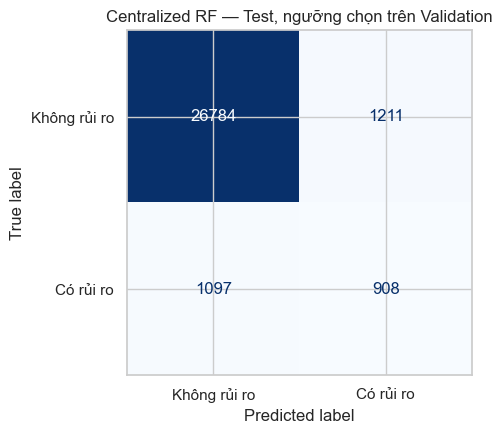

In [13]:
best_threshold = thresholds["best_f1"]
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(test[TARGET],
    (central_scores >= best_threshold).astype(int), labels=[0, 1],
    display_labels=["Không rủi ro", "Có rủi ro"], cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Centralized RF — Test, ngưỡng chọn trên Validation")
plt.tight_layout()
plt.show()

## 7. Lưu metric và đối chiếu Flower Azure

Thư mục results/centralized_seed42_fixed chứa CSV metric ba chính sách, SHA của split và kết quả tuning. Nếu đã tải JSON Flower Azure, ô cuối xuất bảng so sánh 6 hàng sau khi kiểm SHA/cấu hình. Thời gian huấn luyện local và thời gian vòng Azure không phải speedup trên phần cứng đồng nhất.

In [14]:
RESULT_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame(validation_rows).to_csv(RESULT_DIR / "validation_metrics.csv", index=False)
test_metrics.to_csv(RESULT_DIR / "test_metrics.csv", index=False)
cv_results[["rank_test_score", "mean_test_score", "std_test_score",
            "param_rf__max_depth", "param_rf__min_samples_leaf",
            "param_rf__class_weight", "is_protocol_config"]].to_csv(
                RESULT_DIR / "tuning_results.csv", index=False)
(RESULT_DIR / "tuning_summary.json").write_text(json.dumps({
    "scoring": "average_precision", "cv_folds": 3,
    "candidate_count": len(cv_results), "best_params": grid.best_params_,
    "best_cv_ap": float(grid.best_score_), "protocol_rf_config": RF_CONFIG,
    "protocol_cv_ap": protocol_cv_ap,
    "selection_note": "Diagnostic only; baseline and Azure FL use protocol_rf_config",
}, indent=2), encoding="utf-8")
run = {"protocol": "v1.0", "run_id": "central_seed42_fixed",
       "source_sha256": manifest["source_sha256"],
       "split_sha256": manifest["split_sha256"],
       "feature_schema_sha256": manifest["feature_schema_sha256"],
       "rf_config": RF_CONFIG, "central_trees": N_CLIENTS * TREES_PER_CLIENT,
       "client_trees": TREES_PER_CLIENT, "thresholds": {"centralized": thresholds},
       "central_train_seconds": central_train_seconds,
       "test_inference_seconds": {"centralized": test_inference_seconds},
       "source_file_bytes": SOURCE_CSV.stat().st_size}
(RESULT_DIR / "run.json").write_text(json.dumps(run, indent=2), encoding="utf-8")
print("Baseline Test:", RESULT_DIR / "test_metrics.csv")
print("Grid Search:", RESULT_DIR / "tuning_results.csv")
print("Source SHA:", run["source_sha256"], "Test SHA:", run["split_sha256"]["test"])
print("Test best_f1:", test_metrics.loc[test_metrics.policy == "best_f1",
                                       ["roc_auc", "average_precision", "f1", "precision", "recall"]].to_dict("records")[0])

Baseline Test: C:\Users\ACER\Documents\ChatGPT\Project Cloud\results\centralized_seed42_fixed\test_metrics.csv
Grid Search: C:\Users\ACER\Documents\ChatGPT\Project Cloud\results\centralized_seed42_fixed\tuning_results.csv
Source SHA: 1bd46da486a5708c58c7b01a034fae2a13b327f6f7b62ea7ba4fe3b5824b24ac Test SHA: 59db6b4e4fb5b7348d5d4bd8481a39c1e1b80991da8c0b6aca41107e6e412ac5
Test best_f1: {'roc_auc': 0.8668294169024661, 'average_precision': 0.40339624367138077, 'f1': 0.44034917555771097, 'precision': 0.4285040113260972, 'recall': 0.45286783042394013}


### 7.1. So sánh với run Flower Azure nếu có JSON

Cùng script build_comparison.py dùng cho báo cáo sẽ từ chối ghép nếu SHA nguồn/split/schema, tham số RF, số cây hoặc số client không khớp. Thiếu JSON Azure thì baseline và tuning vẫn xuất bình thường.

In [15]:
azure_result = PROJECT_ROOT / "results" / "azure_traffic_new_run" / "flower_seed42_iid_clients5.json"
if azure_result.is_file():
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
    from build_comparison import build
    comparison_path = RESULT_DIR / "comparison_metrics_azure.csv"
    build(RESULT_DIR, azure_result, comparison_path)
    comparison = pd.read_csv(comparison_path)
    display(comparison.loc[comparison.policy == "best_f1",
                           ["model", "execution", "roc_auc", "average_precision",
                            "f1", "precision", "recall", "tn", "fp", "fn", "tp"]].round(4))
else:
    print("Chưa có JSON Flower Azure tại:", azure_result)
    print("Chạy lại ô này sau khi tải JSON của run Azure.")

Wrote 6 comparable policy rows to C:\Users\ACER\Documents\ChatGPT\Project Cloud\results\centralized_seed42_fixed\comparison_metrics_azure.csv


,model,execution,roc_auc,average_precision,f1,precision,recall,tn,fp,fn,tp
2,centralized,centralized_local,0.8668,0.4034,0.4403,0.4285,0.4529,26784,1211,1097,908
3,federated,azure_flower,0.8669,0.4071,0.4433,0.4056,0.4888,26559,1436,1025,980
